In [1]:
# ============ EDIT ONLY THESE LINES ============
DATA_FILE = "data.csv"      # e.g. "house_price.csv".  None = a Choose Files button will appear (Colab)
TARGET    = "price"      # name of the column to predict, e.g. "price".  None = use the LAST column
K_FOLDS   = 10        # number of folds, e.g. 3 or 10
N_SAMPLE  = None      # e.g. 100 to use only 100 random rows.  None = use all rows
TASK      = "regression"    # "auto", "regression" or "classification" (only change if auto guesses wrong)
ONLY      = None      # None = run all 5 algorithms.  Or pick some, e.g. ["Decision Tree"]
                      # names: "Linear Regression"/"Logistic Regression", "K-Nearest Neighbors",
                      #        "Decision Tree", "Random Forest", "Gradient Boosting"
# ===============================================

RANDOM_STATE = 42

## Step 2: Import libraries

In [2]:
import time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import KFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## Step 3: Load the data

In [3]:
if DATA_FILE is None:
    from google.colab import files          # works in Google Colab
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]

data = pd.read_csv(DATA_FILE)
print(f"Loaded '{DATA_FILE}': {data.shape[0]:,} rows, {data.shape[1]} columns")
data.head()

Loaded 'data.csv': 4,600 rows, 18 columns


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


## Step 4: Clean the data


In [4]:
if TARGET is None:
    TARGET = data.columns[-1]
    print(f"TARGET not set -> using the last column: '{TARGET}'")
assert TARGET in data.columns, f"Column '{TARGET}' not found. Columns are: {list(data.columns)}"

before = len(data)
data = data.drop_duplicates().dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Rows removed (duplicates / missing target): {before - len(data):,}")

if N_SAMPLE is not None and N_SAMPLE < len(data):
    data = data.sample(n=N_SAMPLE, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"Using a random sample of {len(data):,} rows")

print(f"Rows used: {len(data):,}")
print("\nMissing values per column (only columns that have some):")
missing = data.isnull().sum()
print(missing[missing > 0] if missing.any() else "none")

Rows removed (duplicates / missing target): 0
Rows used: 4,600

Missing values per column (only columns that have some):
none


## Step 5: Decide the task and choose the features automatically


In [5]:
y = data[TARGET]
y_is_text = (y.dtype == "object") or (str(y.dtype) in ("bool", "category", "string", "str")) or pd.api.types.is_string_dtype(y)
y_few_ints = pd.api.types.is_integer_dtype(y) and y.nunique() <= 10

if TASK == "auto":
    TASK = "classification" if (y_is_text or y_few_ints) else "regression"
print(f"TASK = {TASK.upper()}")
if TASK == "classification":
    print("Class counts:\n", y.value_counts())

numeric_features, categorical_features, dropped = [], [], []
for col in data.columns.drop(TARGET):
    s = data[col]
    n_unique = s.nunique()
    if n_unique <= 1:
        dropped.append((col, "constant column"))
    elif pd.api.types.is_bool_dtype(s):
        data[col] = s.astype(int); numeric_features.append(col)
    elif pd.api.types.is_numeric_dtype(s):
        if pd.api.types.is_integer_dtype(s) and n_unique == len(data) and len(data) > 20:
            dropped.append((col, "looks like an ID (every value different)"))
        else:
            numeric_features.append(col)
    else:
        if n_unique <= 50:
            categorical_features.append(col)
        else:
            dropped.append((col, f"text with too many different values ({n_unique})"))

print(f"\nNumeric features     ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print("Dropped columns      :", dropped if dropped else "none")

X = data[numeric_features + categorical_features]
assert X.shape[1] > 0, "No usable features were found."

TASK = REGRESSION

Numeric features     (12): ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated']
Categorical features (1): ['city']
Dropped columns      : [('date', 'text with too many different values (70)'), ('street', 'text with too many different values (4525)'), ('statezip', 'text with too many different values (77)'), ('country', 'constant column')]


## Step 6: Build the pre-processing pipeline
Everything is done **inside** each fold (so nothing from the test fold leaks into training):
* numbers: fill missing with the median, then scale,
* categories: fill missing with the most common value, then one-hot encode.

In [6]:
parts = []
if numeric_features:
    parts.append(("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                   ("scaler", StandardScaler())]), numeric_features))
if categorical_features:
    parts.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                   ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features))
preprocessor = ColumnTransformer(parts)
print("Pre-processing pipeline ready.")

Pre-processing pipeline ready.


## Step 7: Define the algorithms
(All 5 by default. Use `ONLY` in Step 1 to run just some of them, e.g. only the Decision Tree. To change a Decision Tree setting such as `max_depth`, edit the line below.)

In [7]:
if TASK == "regression":
    algorithms = {
        "Linear Regression": LinearRegression(),
        "K-Nearest Neighbors": KNeighborsRegressor(n_neighbors=5),
        "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    }
    scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
    MAIN, HIGHER_IS_BETTER = "rmse", False
else:
    algorithms = {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    }
    scoring = {"accuracy": "accuracy", "f1": "f1_weighted"}
    MAIN, HIGHER_IS_BETTER = "accuracy", True

if ONLY is not None:
    missing = [a for a in ONLY if a not in algorithms]
    assert not missing, f"Unknown algorithm name(s) {missing}. Choose from: {list(algorithms)}"
    algorithms = {name: model for name, model in algorithms.items() if name in ONLY}

print(f"{TASK.capitalize()} algorithms:", list(algorithms))
print(f"Main score: {MAIN.upper()} ({'higher' if HIGHER_IS_BETTER else 'lower'} is better)")

Regression algorithms: ['Linear Regression', 'K-Nearest Neighbors', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
Main score: RMSE (lower is better)


## Step 8: Set up K-fold cross validation

In [8]:
K = K_FOLDS
if TASK == "classification":
    smallest_class = y.value_counts().min()
    if smallest_class < K:
        K = max(2, int(smallest_class))
        print(f"Smallest class has only {smallest_class} rows -> K reduced to {K}")
    splitter = StratifiedKFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)
    print(f"Using Stratified {K}-fold (every fold keeps the same class proportions)")
else:
    splitter = KFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)
    print(f"Using {K}-fold")

print(f"\nEach round: about {len(X) - len(X)//K:,} rows to train, {len(X)//K:,} rows to test")

Using 10-fold

Each round: about 4,140 rows to train, 460 rows to test


## Step 9: Run K-fold cross validation for all 5 algorithms

In [9]:
fold_scores, rows = {}, []
for name, model in algorithms.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    t0 = time.time()
    res = cross_validate(pipe, X, y, cv=splitter, scoring=scoring)
    secs = time.time() - t0
    row = {"Algorithm": name}
    for m in scoring:
        vals = res[f"test_{m}"]
        if m in ("rmse", "mae"):
            vals = -vals
        fold_scores[(name, m)] = vals
        row[f"Mean {m.upper()}"] = vals.mean()
        if m == MAIN:
            row[f"Std {m.upper()}"] = vals.std()
            row["Best fold"] = vals.max() if HIGHER_IS_BETTER else vals.min()
            row["Worst fold"] = vals.min() if HIGHER_IS_BETTER else vals.max()
    row["Time (s)"] = secs
    rows.append(row)
    print(f"{name:<22} mean {MAIN.upper()} = {row['Mean ' + MAIN.upper()]:>12,.4f}   ({secs:.1f} s)")

summary = pd.DataFrame(rows).sort_values(f"Mean {MAIN.upper()}", ascending=not HIGHER_IS_BETTER).reset_index(drop=True)
summary.insert(0, "Rank", range(1, len(summary) + 1))
print("\nCross validation finished.")

Linear Regression      mean RMSE = 342,605.5535   (0.5 s)
K-Nearest Neighbors    mean RMSE = 427,773.0938   (0.8 s)
Decision Tree          mean RMSE = 554,285.3302   (2.7 s)
Random Forest          mean RMSE = 403,784.5101   (50.7 s)
Gradient Boosting      mean RMSE = 366,397.9416   (7.4 s)

Cross validation finished.


## Step 10: Compare the algorithms

In [10]:
print(f"{MAIN.upper()} of each algorithm on each fold:")
per_fold = pd.DataFrame({name: fold_scores[(name, MAIN)] for name in algorithms})
per_fold.index = [f"Fold {i}" for i in range(1, K + 1)]
display(per_fold.round(4))

RMSE of each algorithm on each fold:


,Linear Regression,K-Nearest Neighbors,Decision Tree,Random Forest,Gradient Boosting
Fold 1,2.118474e+05,2.348871e+05,6.784344e+05,2.738522e+05,2.421031e+05
Fold 2,1.381920e+06,1.385956e+06,1.389004e+06,1.378766e+06,1.377193e+06
Fold 3,2.091428e+05,3.466443e+05,3.431385e+05,2.566048e+05,2.310762e+05
Fold 4,1.696122e+05,3.598682e+05,1.255447e+06,3.867697e+05,2.018199e+05
Fold 5,2.813998e+05,3.811879e+05,3.610907e+05,2.626917e+05,2.705613e+05
Fold 6,2.394497e+05,2.805547e+05,2.707794e+05,2.678188e+05,3.089808e+05
Fold 7,2.260913e+05,3.664757e+05,2.500282e+05,2.229046e+05,2.647865e+05
Fold 8,2.473342e+05,3.005108e+05,3.340913e+05,2.457064e+05,2.499032e+05
Fold 9,2.754337e+05,3.988361e+05,4.007332e+05,4.840861e+05,3.266760e+05
Fold 10,1.838242e+05,2.228099e+05,2.601066e+05,2.586449e+05,1.908797e+05


In [11]:
print("Summary (best algorithm first):")
display(summary.set_index("Rank").round(4))

Summary (best algorithm first):


,Algorithm,Mean RMSE,Std RMSE,Best fold,Worst fold,Mean MAE,Mean R2,Time (s)
Rank,,,,,,,,
1,Linear Regression,342605.5535,348105.6042,169612.1735,1.381920e+06,139137.1661,0.5650,0.5488
2,Gradient Boosting,366397.9416,339310.3007,190879.7307,1.377193e+06,141857.3402,0.4738,7.3679
3,Random Forest,403784.5101,333622.0441,222904.5720,1.378766e+06,140089.4403,0.2965,50.6866
4,K-Nearest Neighbors,427773.0938,324523.7374,222809.8631,1.385956e+06,157981.3949,0.2136,0.8143
5,Decision Tree,554285.3302,402151.2029,250028.1787,1.389004e+06,184041.8353,-1.4399,2.7069


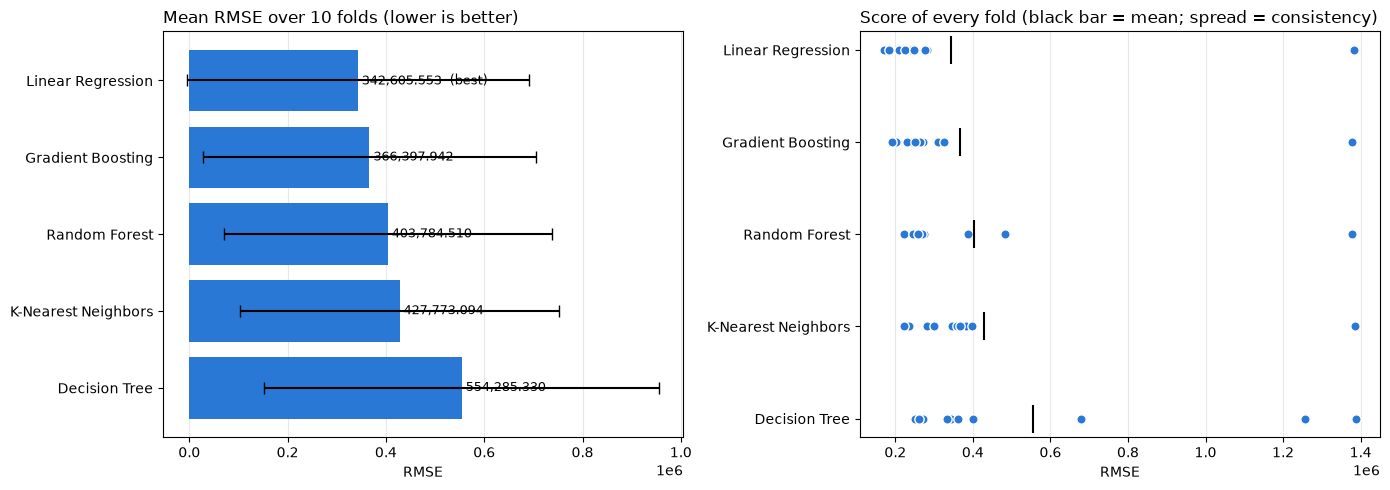

In [12]:
order = summary["Algorithm"].tolist()
means = summary[f"Mean {MAIN.upper()}"].values
stds = summary[f"Std {MAIN.upper()}"].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
pos = np.arange(len(order))
ax1.barh(pos, means, xerr=stds, color="#2a78d6", capsize=4)
ax1.set_yticks(pos, order); ax1.invert_yaxis()
ax1.set_title(f"Mean {MAIN.upper()} over {K} folds ({'higher' if HIGHER_IS_BETTER else 'lower'} is better)", loc="left")
ax1.set_xlabel(MAIN.upper())
for i, v in enumerate(means):
    ax1.text(v, i, f" {v:,.3f}" + ("  (best)" if i == 0 else ""), va="center", fontsize=9)

for i, name in enumerate(order):
    ax2.scatter(per_fold[name], np.full(K, i), s=45, color="#2a78d6", edgecolor="white", zorder=3)
    ax2.scatter(means[i], i, marker="|", s=400, color="black", zorder=4)
ax2.set_yticks(pos, order); ax2.invert_yaxis()
ax2.set_title("Score of every fold (black bar = mean; spread = consistency)", loc="left")
ax2.set_xlabel(MAIN.upper())
for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## Step 11: Train the best algorithm on all the data and save it

In [13]:
best_name = summary.loc[0, "Algorithm"]
best_mean = summary.loc[0, f"Mean {MAIN.upper()}"]
best_std = summary.loc[0, f"Std {MAIN.upper()}"]
print(f"Best algorithm : {best_name}")
print(f"Expected {MAIN.upper()} : {best_mean:,.4f} (+/- {best_std:,.4f})")

final_model = Pipeline([("preprocessor", preprocessor), ("model", algorithms[best_name])])
final_model.fit(X, y)

MODEL_FILE = "best_model.pkl"
with open(MODEL_FILE, "wb") as f:
    pickle.dump({"model": final_model, "features": list(X.columns), "task": TASK, "target": TARGET}, f)
print(f"Model trained on {len(X):,} rows and saved as '{MODEL_FILE}'")

Best algorithm : Linear Regression
Expected RMSE : 342,605.5535 (+/- 348,105.6042)
Model trained on 4,600 rows and saved as 'best_model.pkl'


In [15]:
import json

# Gather metadata about the features so the Streamlit app knows how to build the UI
features_meta = {}
for col in X.columns:
    if col in numeric_features:
        features_meta[col] = {
            "dtype": "numeric",
            "median": float(X[col].median())
        }
    else:
        # For categorical, get the top 20 most common values
        features_meta[col] = {
            "dtype": "categorical",
            "top_values": X[col].value_counts().index[:20].tolist()
        }

# Gather overall model info
model_info = {
    "best_algorithm": best_name,
    "n_rows": len(X),
    "task": TASK,
    "target": TARGET,
    "cv_mean_rmse": float(best_mean) if TASK == "regression" else 0,
    "cv_mean_mae": float(summary.loc[0, "Mean MAE"]) if TASK == "regression" else 0,
    "features_meta": features_meta
}

# Save it to disk
with open("model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)
    
print("Saved model_info.json for the Streamlit app.")

Saved model_info.json for the Streamlit app.


In [16]:
# ============ DOWNLOAD FILES TO YOUR COMPUTER ============
from google.colab import files
import os

for fname in ["best_model.pkl", "model_info.json"]:
    if os.path.exists(fname):
        print(f"Downloading {fname} ...")
        files.download(fname)
    else:
        print(f"⚠️ {fname} not found — did the previous cells run?")

ModuleNotFoundError: No module named 'google'

## Step 12: Predict for a new record
The input questions are created **automatically** from your feature names.
By default it uses a typical record (median for numbers, most common value for categories). To type your own values, set `USE_INTERACTIVE_INPUT = True`.

In [14]:
USE_INTERACTIVE_INPUT = False

def typical_value(col):
    return float(X[col].median()) if col in numeric_features else X[col].mode().iloc[0]

new_record = {}
for col in X.columns:
    default = typical_value(col)
    if USE_INTERACTIVE_INPUT:
        hint = f" (e.g. {default})" if col in numeric_features else f" (e.g. {X[col].value_counts().index[:5].tolist()})"
        raw = input(f"{col}{hint}: ").strip()
        new_record[col] = float(raw) if col in numeric_features else raw
    else:
        new_record[col] = default

print("New record:")
for k, v in new_record.items():
    print(f"  {k:<25}: {v}")

with open(MODEL_FILE, "rb") as f:
    saved = pickle.load(f)
prediction = saved["model"].predict(pd.DataFrame([new_record])[saved["features"]])[0]

print()
if TASK == "regression":
    print(f"Predicted {TARGET}: {prediction:,.2f}")
    print(f"Typical error (cross-validation RMSE of {best_name}): about {best_mean:,.2f}")
else:
    print(f"Predicted {TARGET}: {prediction}")
    print(f"Expected accuracy (cross validation of {best_name}): {best_mean:.1%}")

New record:
  bedrooms                 : 3.0
  bathrooms                : 2.25
  sqft_living              : 1980.0
  sqft_lot                 : 7683.0
  floors                   : 1.5
  waterfront               : 0.0
  view                     : 0.0
  condition                : 3.0
  sqft_above               : 1590.0
  sqft_basement            : 0.0
  yr_built                 : 1976.0
  yr_renovated             : 0.0
  city                     : Seattle

Predicted price: 561,287.37
Typical error (cross-validation RMSE of Linear Regression): about 342,605.55


## Step 13: Your observations (write these yourself after looking at your results)

Answer in 4 to 6 sentences:
1. Which algorithm is best (lowest RMSE / highest accuracy)? Which is worst?
2. Are the top two close, compared with the standard deviation? If yes, they are practically tied.
3. Is the result consistent across folds, or does one fold stand out? Why might that be?
4. Which algorithm was the slowest, and is its extra time worth the accuracy?
5. How would the result change with more data or different K?